# Laboratorio 2C · Escribir, revisar y ejecutar un plan.md

Jueves 22 de octubre de 2026, 12:30, Planta Sur de **MantenIA**. El compresor 2 vibra a 7,1 mm/s, por encima del límite de 4,5 mm/s, y hay que cambiar los rodamientos de su motor. Producción dio una ventana de 13:00 a 17:00. El supervisor de mantenimiento le pide a un asistente de IA que redacte el plan de la intervención y se lo pasa a usted y a su pareja: *«Revísenlo antes de aprobarlo. Si lo aprueban, ustedes responden por él»*.

Un **plan.md** es un archivo de texto en formato Markdown donde un agente basado en un LLM, o una persona junto con el agente, escribe el plan de una tarea **antes** de ejecutarla, y lo mantiene al día **mientras** la ejecuta. Es un plan clásico (meta, pasos, dependencias, monitoreo y replanificación) escrito en lenguaje natural. A diferencia del plan PDDL de los laboratorios 2A y 2B, no hay un validador formal: verifican una persona, con una **lista de chequeo**, y las comprobaciones que el propio plan declara en cada paso.

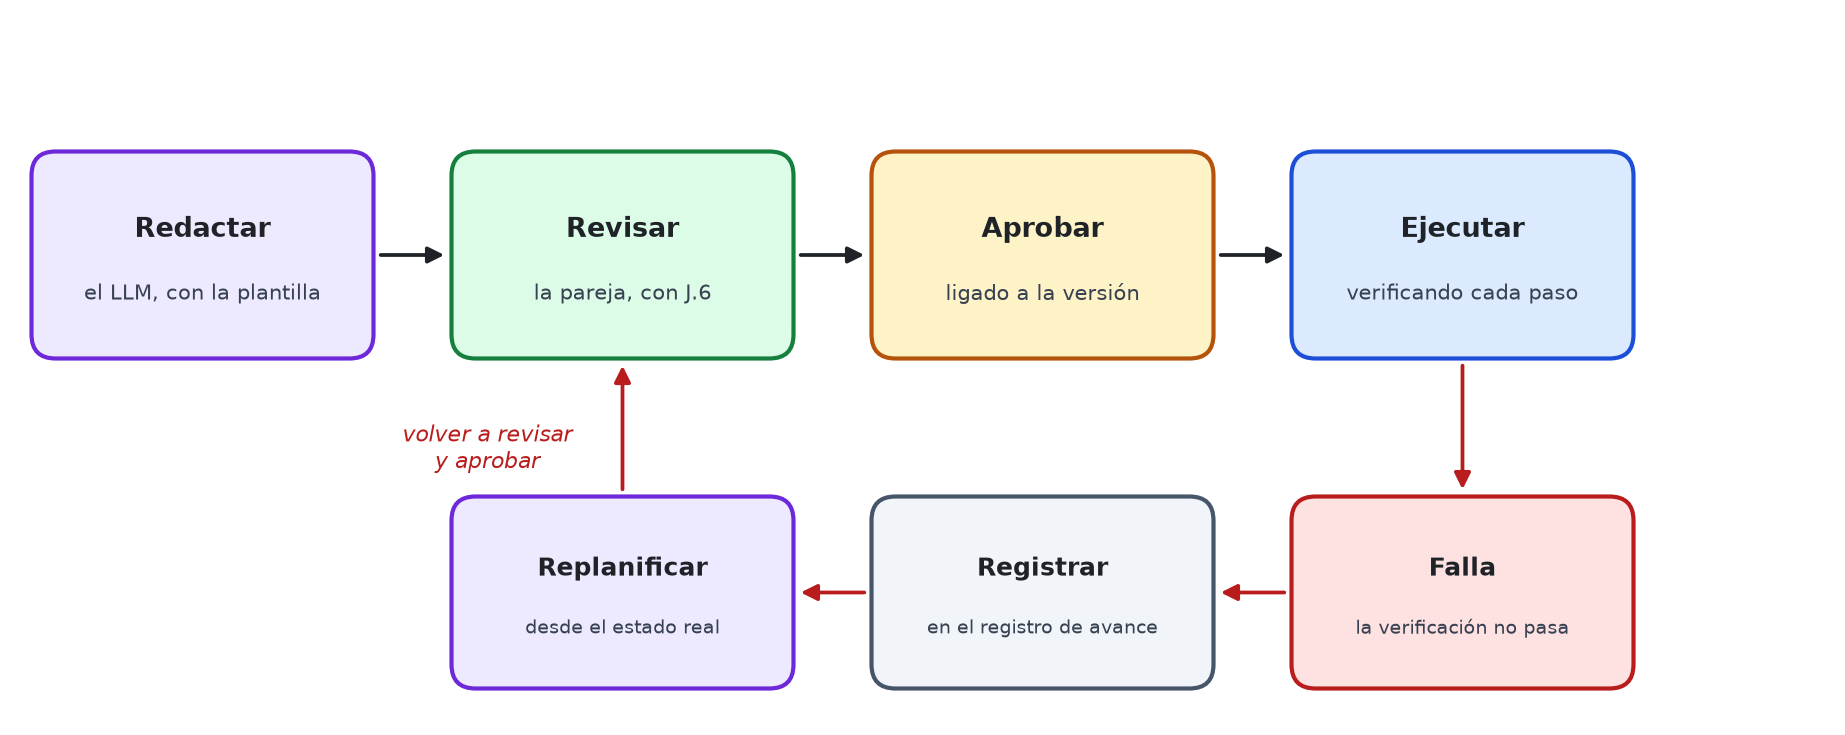

En este laboratorio usted:
* Pedirá a un LLM el plan.md de la orden OT-523 y lo revisará con la **lista de chequeo J.6**, con ayuda de un revisor automático que solo mira la forma.
* Corregirá el plan y lo aprobará. La aprobación queda ligada a esa versión: si alguien lo cambia, deja de estar aprobado.
* Lo ejecutará en un simulador de la intervención: cada casilla se marca solo si su verificación pasa.
* En casa, ante la falla, registrará, replanificará con ayuda del LLM, volverá a aprobar y terminará.

| | |
| :--- | :--- |
| **Resultado de aprendizaje** | RA4: especificar planes explícitos y verificables (plan.md) para agentes basados en LLMs. |
| **Tiempo** | 40 minutos en clase (secciones 0 a 7) y cerca de una hora en casa (secciones 8 a 10). |
| **Modalidad** | En parejas. |
| **Entrega** | Este notebook ejecutado y la carpeta `planes/`, con todas las versiones del plan, al inicio de la semana 2 del curso (detalles en la sección 10). |

## Contenido

* [Antes de empezar](#0)
* [1 - Qué es un plan.md](#1)
* [2 - Los documentos de la OT-523](#2)
* [3 - El LLM redacta el plan](#3)
* [4 - Revisar con la lista de chequeo](#4)
* [5 - Corregir y aprobar](#5)
* [6 - Ejecutar con verificación](#6)
* [7 - ¿Quién detectó qué? Discusión de cierre](#7)
* [8 - Replanificar, volver a aprobar y terminar](#8) · *para casa*
* [9 - La revisión completa y el análisis](#9) · *para casa*
* [10 - Inténtelo usted mismo, entrega y criterios](#10)
* [Conclusión](#conclusion)
* [Referencias](#referencias)

<details>
<summary><b>💡 Otra forma de navegar: el panel Esquema de VS Code</b> (clic para desplegar)</summary>

VS Code lista todos los títulos de este notebook en el panel **Esquema** (*Outline*), dentro del Explorador de la barra lateral izquierda. Al hacer clic en un título, el notebook salta a esa sección. Si algún enlace de esta tabla no lo lleva a su sección, use el Esquema.

</details>

<a id='0'></a>
## Antes de empezar

Ejecute las celdas **en orden**. Solo se editan las celdas marcadas con ✏️ y, en las secciones 5 y 8, el archivo del plan. Todo lo que hace la pareja queda en la carpeta `planes/`: si cierra VS Code o reinicia el kernel, ejecute de nuevo la sección 0 y siga donde iba.

<details>
<summary><b>Cómo usar este notebook en VS Code</b> (si es su primera vez)</summary>

1. Con **Archivo › Abrir carpeta**, abra la carpeta del curso: la que contiene el entorno `.venv` y las carpetas de los laboratorios.
2. En el Explorador, abra el notebook del laboratorio (el archivo `.ipynb`). El notebook trabaja desde su propia carpeta, donde están sus módulos y sus datos.
3. Haga clic en **Seleccionar kernel** (arriba a la derecha) y elija el entorno `.venv` del curso, el que creó en la fase previa con la guía de instalación.
4. Ejecute cada celda con **Shift + Enter** o con el botón ▷ de su izquierda.
5. Si algo falla, lea el mensaje: los módulos de apoyo explican en español qué revisar.

</details>

**El LLM.** Redacta el plan y, en casa, propone la replanificación. El notebook usa la primera vía disponible: una clave de API, un modelo local o respuestas grabadas de una corrida anterior. Los documentos de la OT-523 son ficticios: no envíe a un LLM documentos reales de su organización sin autorización.

<details>
<summary><b>Las tres vías de acceso a un LLM</b> (clic para desplegar)</summary>

1. **La API de un proveedor**, con una clave guardada en un archivo `.env` de esta carpeta o de una superior: una línea como `ANTHROPIC_API_KEY=su-clave`, sin espacios ni comillas. **Nunca** escriba la clave en el notebook: el `.env` no se entrega.
2. **Un modelo local** con Ollama, sin clave ni costo, si lo instaló en la fase previa.
3. **Respuestas grabadas** de una corrida real anterior. El notebook corre completo, pero la replanificación grabada corresponde al plan de referencia del docente, no al suyo: sirve como guía.

</details>

<details>
<summary><b>Respaldo: trabajar en Google Colab</b> (solo si no puede instalar el entorno)</summary>

1. Abra el notebook en [Colab](https://colab.research.google.com/) con **Archivo › Subir notebook** y suba a la carpeta `/content` el mismo `lab_2C_plan_md.zip` que le entregó el docente.
2. Si tiene una clave de API, guárdela en los **Secrets** de Colab con el nombre `ANTHROPIC_API_KEY`.
3. Para editar el plan, ábralo con doble clic desde el panel **Archivos** de Colab (`/content/lab_2C_plan_md/planes/plan_OT-523.md`).

</details>

* Ejecute la siguiente celda para preparar el entorno.

In [ ]:
# Preparar el entorno: comprobar Python e instalar lo que falte de requirements.txt
import os, pathlib, sys, zipfile
if "google.colab" in sys.modules and not pathlib.Path("entorno.py").exists():
    # Respaldo en Colab: descomprimir la carpeta del laboratorio que usted subió como .zip
    zipfile.ZipFile("/content/lab_2C_plan_md.zip").extractall("/content")
    os.chdir("/content/lab_2C_plan_md")
import entorno
entorno.preparar()

El laboratorio usa varios módulos de apoyo, en la misma carpeta del notebook.

<details>
<summary><b>Qué hace cada módulo</b> (clic para desplegar)</summary>

* `plan_md`: guarda el plan y sus versiones, lee sus pasos, marca casillas, escribe en el registro de avance y registra las **aprobaciones**. Cada aprobación queda ligada a una **huella** del plan: un código calculado a partir de todo su contenido, salvo las entradas del registro y las casillas. Si alguien cambia algo después de aprobar, la huella cambia y el plan deja de estar aprobado.
* `revisor_plan`: comprueba los aspectos mecánicos de la lista de chequeo J.6.
* `simulador_ot523`: simula la intervención, con su reloj, y ejecuta el plan paso a paso.
* `redaccion_2c`: arma las instrucciones para el LLM.
* `cliente_llm` y `presentacion`, los mismos del Laboratorio 2B.

</details>

* Ejecute la siguiente celda para importar los módulos.

In [ ]:
# Importar los módulos de apoyo del laboratorio
import presentacion as p
import cliente_llm
import plan_md
import revisor_plan as revisor
import simulador_ot523 as simulador
import redaccion_2c as redaccion

### 0.1 - Elegir el LLM

* Ejecute la siguiente celda para ver qué vías de acceso a un LLM están disponibles en su computador. No muestra ninguna clave.

In [ ]:
# Ver qué vías de acceso a un LLM están disponibles (no muestra ninguna clave)
p.mostrar_tabla(cliente_llm.estado_proveedores(), titulo="Vías de acceso a un LLM en este computador")

Con `None`, el notebook elige la primera vía disponible. Redactar un plan genera unas 1 000 palabras: con la API toma segundos; con un modelo local en un portátil sin GPU, varios minutos. En clase, prefiera la API o las respuestas grabadas.

* Ejecute la siguiente celda para crear el cliente del LLM.

In [ ]:
# ✏️ Configuración del LLM: deje None para que el notebook elija la primera vía disponible
PROVEEDOR = None    # "anthropic", "openai", "gemini", "ollama" o "grabado"
MODELO_LLM = None   # None usa el LLM por defecto del proveedor
llm = cliente_llm.ClienteLLM(proveedor=PROVEEDOR, modelo=MODELO_LLM)

<a id='1'></a>
## 1 - Qué es un plan.md

Los asistentes de programación con IA convirtieron la planificación explícita en una práctica diaria: antes de tocar nada, el agente investiga, escribe un plan en Markdown y espera a que una persona lo apruebe. Un plan explícito es, a la vez, un **contrato revisable** (se corrige antes de actuar, cuando corregir es barato), una **memoria externa** (vive fuera del LLM, así que la tarea se puede retomar) y una herramienta de **monitoreo** (las casillas y el registro muestran qué se hizo, qué falló y qué cambió).

El curso usa una estructura de ocho secciones, la de `plantilla_plan.md` (Anexo J del programa del curso):

| Sección | Qué contiene |
| :--- | :--- |
| Objetivo | El resultado esperado, verificable: con plazo y con criterio medible |
| Contexto | Estado actual; fuentes, sistemas y datos; supuestos |
| Alcance | Qué incluye y, de forma explícita, qué queda fuera |
| Restricciones | Normas, plazos, presupuesto, herramientas permitidas, datos sensibles: lo que no se negocia |
| Pasos | Lista numerada con casillas: acción, resultado, dependencias y verificación |
| Criterios de aceptación | Una verificación de extremo a extremo |
| Riesgos y aprobaciones | Riesgos con su señal y su respuesta; pasos que aprueba una persona |
| Registro de avance | Bitácora con fecha y hora: pasos cumplidos, desviaciones y decisiones |

Tres principios pesan más que los demás: un **objetivo verificable**, **cada paso con su verificación** y un **fuera de alcance declarado**. Y uno los resume a todos: **una casilla marcada no es una prueba**. La verificación debe ser externa a quien ejecuta, el mismo principio del marco LLM-Modulo del Laboratorio 2B.

<details>
<summary><b>Para profundizar: dónde aparece, su relación con la planificación clásica y los errores frecuentes</b> (clic para desplegar)</summary>

**El mismo patrón en seis herramientas**, según su documentación oficial: Claude Code (modo de planificación: nada cambia hasta que la persona aprueba), Cursor (`.plan.md`), Kiro (`tasks.md`, tareas ligadas a requisitos), GitHub Spec Kit (`plan.md` y `tasks.md`, con casillas `[ ]` que se marcan `[X]`), OpenAI Codex (`PLANS.md`, un documento vivo) y Manus (`todo.md`, una lista que el agente reescribe para no perder el objetivo).

**Un plan clásico, escrito para personas.** El objetivo y los criterios de aceptación son la **meta**; el contexto y los supuestos, el **estado inicial**; los pasos con dependencias, las **acciones con precondiciones**; las fases, la **descomposición jerárquica**; las casillas y el registro, el **monitoreo**; la actualización ante una falla, la **replanificación**; y la revisión humana, la **validación**. Al plan PDDL lo valida una máquina contra un modelo; al plan.md, una persona y las verificaciones que el plan declara.

**El proceso, en cinco pasos:** explorar sin actuar, redactar, revisar y aprobar, ejecutar con verificación y mantener el plan vivo (ante una falla: registrar, replanificar por escrito y volver a aprobar).

**Errores frecuentes:** objetivo vago; pasos sin verificación; sin «fuera de alcance»; plan que no se actualiza; plan tan detallado que nadie lo mantiene; actuar mientras se planifica; y aprobar sin leer.

Fuente: guía del plan.md del programa del curso (Anexo J), basada en la documentación oficial de las herramientas citadas en las referencias.

</details>

En casa, si quiere ver un plan.md completo y correcto, use el ejemplo de la orden OT-512 después de una replanificación, en `ejemplos/plan_OT-512_J8.md`.

* Ejecute la siguiente celda si quiere ver ese ejemplo ahora (es opcional).

In [ ]:
# Opcional: mostrar el plan.md de ejemplo de la OT-512 (Anexo J.8 del programa del curso)
p.mostrar_archivo("ejemplos/plan_OT-512_J8.md", "plan.md de la OT-512, después de una replanificación")

<a id='2'></a>
## 2 - Los documentos de la OT-523

Antes de planificar, se explora sin actuar. Estos son los seis documentos de la intervención: la orden de trabajo, el inventario, las certificaciones, el procedimiento del fabricante, la norma interna de bloqueo y etiquetado (MNT-07) y la ventana acordada con producción. El LLM recibirá exactamente estos documentos, y el plan que ustedes aprueben debe respetar todo lo que dicen.

> **Nota:** las certificaciones cambian con el tiempo. Lea la vigencia de cada una en el documento 3, aunque recuerde a alguien certificado en otra orden.

* Ejecute la siguiente celda para ver los documentos.

In [ ]:
# Mostrar los seis documentos de la OT-523 (ficticios)
for archivo in sorted(pathlib.Path("documentos").iterdir()):
    p.mostrar_archivo(archivo)

<a id='3'></a>
## 3 - El LLM redacta el plan

La instrucción le da al LLM la plantilla, los seis documentos y la lista de **acciones disponibles** en la intervención, con reglas precisas: usar solo información de los documentos, declarar como supuesto lo que falte, escribir cada paso con una sola acción, su resultado y su verificación, y dejar el registro vacío.

**Desglose del experimento**

| | |
| :--- | :--- |
| **Entrada** | La plantilla, los seis documentos y las acciones disponibles. |
| **Qué debería pasar** | Un plan.md con las ocho secciones, que respete el procedimiento, la norma de bloqueo, las certificaciones y la ventana. |
| **Cómo puede fallar** | Inventar datos, omitir restricciones que solo aparecen en un documento, dejar pasos sin verificación, prever mal los riesgos o las aprobaciones. |

El plan se guarda en `planes/plan_OT-523.md` y, como versión 1, en `planes/plan_OT-523_v1_llm.md`. Si la carpeta `planes/` ya tiene un plan, la celda lo conserva con sus correcciones: volver a ejecutarla no borra su trabajo. Para empezar de cero, ejecute `plan.reiniciar()` y luego esta celda.

* Ejecute la siguiente celda para pedir el plan al LLM y verlo.

In [ ]:
# Pedir al LLM el plan.md de la OT-523 (versión 1); si ya hay un plan en planes/, se conserva
plan = plan_md.PlanMD("planes/plan_OT-523.md")
if plan.existe():
    p.nota("Ya hay un plan en planes/plan_OT-523.md: se conserva con sus correcciones.", "info")
else:
    texto, respuesta = redaccion.redactar(llm)
    if texto:
        plan.guardar(texto)
        plan.guardar_version("v1_llm")
        p.nota(f"Plan recibido de {respuesta.modelo} en {respuesta.segundos} s "
               f"({respuesta.tokens_entrada} tokens de entrada y {respuesta.tokens_salida} de salida).", "info")
    else:
        p.nota("No se obtuvo el plan. Configure una vía de acceso a un LLM (sección 0.1).", "error")
if plan.version("v1_llm").exists():
    p.mostrar_markdown(plan.version("v1_llm").read_text(encoding="utf-8"))

<a id='4'></a>
## 4 - Revisar con la lista de chequeo

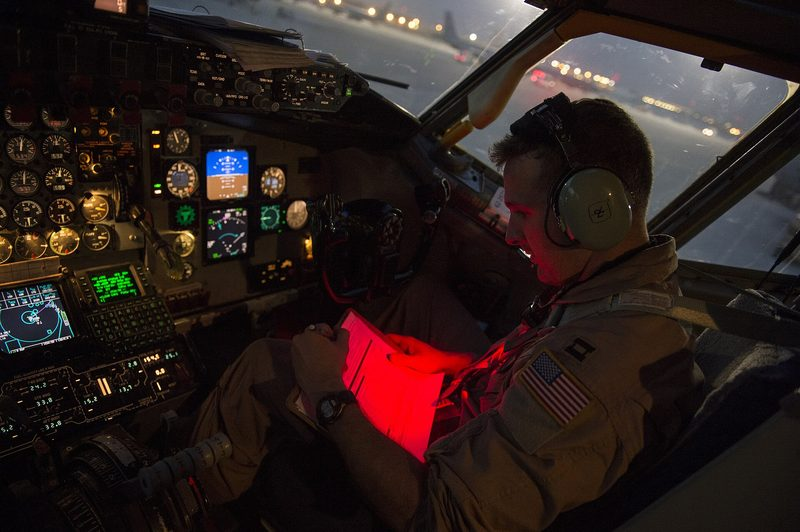

*El mismo principio en aviación: la lista de chequeo prevuelo hace explícitos los pasos y su verificación, y no depende de la memoria del piloto. U.S. Air Force (2014), dominio público, [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Running_the_checklist_%2814729226029%29.jpg).*

Antes de aprobar, el plan se revisa con los diez puntos de la **lista de chequeo J.6**, la que está al final de `plantilla_plan.md`:

1. El objetivo se puede comprobar con una verificación concreta.
2. El contexto nombra las fuentes, sistemas y datos involucrados, y declara los supuestos.
3. Hay una sección explícita de lo que queda fuera del alcance.
4. Las restricciones no negociables están escritas.
5. Cada paso tiene una acción, un resultado esperado y una verificación.
6. Las dependencias entre pasos son explícitas.
7. Los pasos irreversibles o costosos piden aprobación humana.
8. Los criterios de aceptación incluyen una verificación de extremo a extremo.
9. Los riesgos principales tienen una señal de alerta y una respuesta.
10. El registro de avance está al día y cada replanificación dice qué cambió y por qué.

El **revisor automático** comprueba la **forma**: que exista cada sección, que cada paso tenga verificación, que haya una aprobación antes de arrancar. No puede juzgar el **contenido**: si los datos son los de los documentos, si falta una restricción, si las respuestas a los riesgos respetan las normas. Eso le toca a la pareja.

* Ejecute la siguiente celda para ver la revisión automática del borrador del LLM.

In [ ]:
# Revisión automática (solo la forma) del borrador que redactó el LLM (versión 1)
borrador = plan_md.PlanMD(str(plan.version("v1_llm")))
revision_1 = revisor.revisar(borrador)
revisor.mostrar_revision(revision_1, "Revisión automática del borrador del LLM (versión 1)")

### ✏️ Los hallazgos de la pareja

Lean el borrador contra los documentos y escriban **al menos tres problemas**. Para cada uno: el punto de J.6 que incumple, qué está mal y dónde, y qué documento lo muestra. Busquen sobre todo lo que el revisor no puede ver:
* datos que no coinciden con los documentos, o que no están en ellos;
* restricciones de un solo documento que el plan olvidó;
* riesgos cuya respuesta no respeta las normas o la ventana;
* pasos que sobran, o dependencias que no corresponden.

La revisión completa, punto por punto, queda para casa (sección 9).

* Complete la lista y ejecute la celda. La comparación pone sus hallazgos al lado de la revisión automática.

In [ ]:
# ✏️ Hallazgos de la pareja: (punto de J.6, qué está mal y dónde, qué documento lo muestra)
hallazgos = [
    (..., "...", "..."),
    (..., "...", "..."),
    (..., "...", "..."),
]
revisor.comparar_hallazgos(hallazgos, revision_1)

<a id='5'></a>
## 5 - Corregir y aprobar

Ahora corrijan el plan en su archivo:

1. En el Explorador de VS Code, abra `planes/plan_OT-523.md`.
2. Corrija lo que encontraron y guarde con **Ctrl + S** (en macOS, **Cmd + S**).
3. Vuelva a ejecutar la revisión con la celda de más abajo. Repita hasta que el plan cumpla los nueve primeros puntos: el 10 se cumple al ejecutar.

**Reglas de formato.** El simulador ejecuta el plan leyendo sus pasos, así que:
* cada paso va en una línea, con este formato: `- [ ] 7. APROBACIÓN: ... (requiere 6) → Resultado: ... · Verificación: ...`, numerados 1, 2, 3...;
* **un paso, una operación**: cada paso empieza con el verbo de una de las operaciones del simulador (la tabla de abajo). Lo que no es una operación, como verificar la referencia o calentar los rodamientos, va dentro del resultado o de la verificación del paso que lo cumple;
* el paso de APROBACIÓN también lleva resultado y verificación;
* lo que solo ocurre si algo falla no va en los pasos, sino en los riesgos: un plan lineal ejecuta todos sus pasos.

* Ejecute la siguiente celda para ver las operaciones del simulador y cómo leería cada paso de su plan actual.

In [ ]:
# Operaciones del simulador y cómo leería cada paso del plan actual (no ejecuta nada)
simulador.mostrar_operaciones()
simulador.mostrar_correspondencia(plan)

<details>
<summary><b>Pistas: lo que suelen olvidar los planes redactados por un LLM</b> (clic para desplegar)</summary>

* Un objetivo **con plazo** y con un criterio medible.
* Las restricciones que viven en documentos distintos: certificación **vigente**, la referencia exacta del rodamiento, quién puede retirar un candado, la **ventana** y su límite.
* Una respuesta a cada riesgo que respete las normas: ¿quién debe aprobar si el trabajo pasa de las 17:00?, ¿qué hace falta para volver a arrancar después de una corrección?
* Dependencias que correspondan: ¿de verdad bloquear depende de retirar los rodamientos?

</details>

* Después de corregir y guardar el archivo, ejecute la celda siguiente para revisarlo de nuevo.

In [ ]:
# ✏️ Después de corregir y guardar planes/plan_OT-523.md en VS Code, revíselo de nuevo
revision_2 = revisor.revisar(plan)
revisor.mostrar_revision(revision_2, "Revisión automática del plan corregido")
simulador.mostrar_correspondencia(plan)

### ✏️ Aprobar el plan

Cuando el plan cumpla la lista de chequeo y el simulador pueda leer cada paso, apruébenlo. La pareja hace de revisora: escriban sus nombres. La aprobación queda en el registro de avance, a las 12:45 simuladas, con la huella de esta versión.

* Escriba sus nombres y ejecute la celda.

In [ ]:
# ✏️ Aprobación: escriban sus nombres (la pareja hace de revisora del plan)
APRUEBAN = "..."
if APRUEBAN.strip() in ("", "..."):
    p.nota("Escriban sus nombres en APRUEBAN antes de aprobar.", "aviso")
elif simulador.hay_ejecucion(plan):
    p.nota("La intervención ya empezó: esta aprobación no se repite. Si cambiaron el plan después de la falla, "
           "apruébenlo en la sección 8.3.", "info")
elif plan.aprobado():
    p.nota("El plan ya está aprobado en su versión actual.", "info")
else:
    version = plan.aprobar(por=APRUEBAN, cargo="revisores del plan", hora="12:45")
    plan.guardar_version("v2_aprobado")
    p.nota(f"Plan aprobado · versión {version}. Si lo modifican, tendrán que volver a aprobarlo.", "exito")

<a id='6'></a>
## 6 - Ejecutar con verificación

El simulador reproduce la intervención con un reloj que empieza a las 13:00. `ej.ejecutar()` recorre los pasos pendientes del plan, en orden:

1. Comprueba que el plan esté **aprobado en su versión actual**. Si no, no ejecuta.
2. Lee cada paso, reconoce su operación y la ejecuta en el simulador, que devuelve una **observación**: qué se vio y si la verificación pasó.
3. Si pasa, **marca la casilla** y escribe en el registro de avance la hora y la evidencia.
4. Si falla, **no marca** la casilla, registra la falla y se detiene hasta que se replanifique.

La ejecución se guarda en `planes/ejecucion.json`, así que se puede retomar después. En algún momento ocurrirá una **falla**. El docente puede asignar un escenario distinto a cada pareja:

| Escenario | Qué pasa |
| :--- | :--- |
| `"rodamiento_equivocado"` | La caja rotulada 6206-2RS trae rodamientos de otra referencia. |
| `"vibracion_alta"` | Después del cambio, la prueba de vibración falla. |
| `"tecnico_ausente"` | La técnica asignada es llamada a una emergencia en medio de la intervención. |

* Elija el escenario en la celda siguiente y ejecútela. Si el docente no asignó uno, deje `"vibracion_alta"`. Lea cada observación: cuando ocurra la falla, la ejecución se detiene.

In [ ]:
# ✏️ Escenario de falla y ejecución del plan aprobado, paso a paso
ESCENARIO = "vibracion_alta"     # "rodamiento_equivocado", "vibracion_alta" o "tecnico_ausente"
ej = simulador.Ejecucion(plan, ESCENARIO)
ej.ejecutar()

<a id='7'></a>
## 7 - ¿Quién detectó qué? Discusión de cierre

En este laboratorio actúan cuatro tipos de verificación, cada uno con un alcance distinto:

| Verificación | Qué puede detectar | Qué no puede detectar |
| :--- | :--- | :--- |
| **Revisión humana** (la pareja, con J.6) | Datos equivocados, restricciones olvidadas, riesgos mal resueltos | Lo que la persona no sabe o no lee con atención |
| **Revisor automático** | Secciones, verificaciones, dependencias o aprobaciones que faltan en la forma | Si el contenido es correcto |
| **Ejecución con verificación** (el simulador) | Lo que no resulta como se esperaba: la referencia, la vibración, la ausencia, una aprobación que falta | Lo que ninguna verificación del plan mira |
| **Validador formal** (PDDL, como en 2A y 2B) | Pasos que violan precondiciones del modelo | Lo que el modelo no representa: plazos, aprobaciones, mediciones, el alcance |

Para cerrar la clase, discutan en pareja, sin escribir (si no alcanza el tiempo, háganlo al empezar en casa):
* ¿Cuáles de sus hallazgos de la sección 4 habría detectado el revisor automático?, ¿y un validador PDDL?
* ¿Qué detectó la ejecución que nadie había visto al revisar?
* ¿Qué habría pasado si hubieran aprobado el borrador sin leerlo?

---

### ⏸ Hasta aquí, el trabajo en clase

Las secciones 8 a 10 se trabajan en casa: cerca de una hora. Al retomar, ejecute de nuevo la sección 0; el plan y la ejecución siguen en `planes/`.

---

<a id='8'></a>
## 8 - Replanificar, volver a aprobar y terminar

<a id='8-1'></a>
### 8.1 - La propuesta del LLM

La falla ya quedó en el registro de avance, con su hora y lo que se observó: la detectó la verificación de un paso. Ahora toca **replanificar por escrito**, desde el estado real y no desde el principio: conservar los pasos cumplidos, tachar el que falló, agregar los pasos nuevos con su verificación, actualizar el objetivo, los riesgos y los criterios si cambian, y pedir las aprobaciones que exigen los documentos.

El LLM propondrá el plan actualizado. La propuesta se guarda aparte, en `planes/plan_OT-523_v3_propuesta_llm.md`, y es un **borrador**: no cambia su plan hasta que ustedes decidan.

* Ejecute la siguiente celda para retomar el plan y la ejecución, y pedir la propuesta al LLM. Muestra qué cambió y la revisión automática de la propuesta.

In [ ]:
# Retomar el plan y la ejecución desde planes/, y pedir al LLM una propuesta de replanificación
plan = plan_md.PlanMD("planes/plan_OT-523.md")
ej = simulador.retomar(plan)   # retoma la ejecución guardada, con su escenario
if ej is None or ej.falla is None:
    p.nota("Todavía no hay una falla registrada: ejecute los pasos de la sección 6.", "aviso")
else:
    if not plan.version("v2_en_ejecucion").exists():
        plan.guardar_version("v2_en_ejecucion")   # el plan tal como estaba al fallar
    propuesta, respuesta = redaccion.replanificar(llm, plan, ej.falla, ej.escenario)
    if propuesta is None:
        p.nota("No se obtuvo la propuesta. Configure una vía de acceso a un LLM (sección 0.1).", "error")
    else:
        plan.version("v3_propuesta_llm").write_text(propuesta.strip() + "\n", encoding="utf-8")
        if not respuesta.coincide:
            p.nota("Con respuestas grabadas, esta es la replanificación del plan de referencia del docente, no la del "
                   "suyo: úsela como guía para editar su plan a mano, y no la adopte.", "aviso")
        p.mostrar_diferencias(plan.texto, propuesta, "plan en ejecución", "propuesta del LLM")
        revisor.mostrar_revision(revisor.revisar(plan_md.PlanMD(str(plan.version("v3_propuesta_llm")))),
                                 "Revisión automática de la propuesta")

<a id='8-2'></a>
### 8.2 - Revisar la propuesta y corregir el plan

La propuesta se revisa con la misma lista de chequeo. Además, en una replanificación conviene buscar estos errores típicos:
* ¿Tachó **solo** el paso que falló, sin marcarlo como cumplido, y agregó pasos que lo reemplazan?
* ¿Pidió las **aprobaciones** que exigen los documentos? Por ejemplo, la extensión de la ventana si el trabajo pasa de las 17:00, o una nueva autorización para volver a arrancar.
* ¿Inventó datos, o borró entradas del registro de avance?
* ¿Lo que dice en el registro coincide con lo que cambió en los pasos?

Si la propuesta corresponde a su plan (con la API o el modelo local), pueden **adoptarla** y corregirla después. Si no, editen su plan a mano, usándola como guía. Adoptarla conserva las entradas de su registro.

* Elija si adopta la propuesta (`ADOPTAR`) y ejecute la celda.

In [ ]:
# ✏️ ¿Adoptar la propuesta del LLM como punto de partida? (True solo si corresponde a su plan)
ADOPTAR = False
adoptada = plan.ruta.parent / "propuesta_adoptada"   # marca: la propuesta se adopta una sola vez
if ADOPTAR and not adoptada.exists():
    recuperadas = plan.adoptar(plan.version("v3_propuesta_llm"))
    adoptada.touch()
    p.nota(f"Propuesta adoptada; se conservaron {recuperadas} entradas del registro. Ahora revísela y corríjala.", "info")
elif ADOPTAR:
    p.nota("La propuesta ya se había adoptado: su plan conserva las correcciones que le hizo después.", "info")
else:
    p.nota("Su plan no cambió. Edítelo a mano en planes/plan_OT-523.md, usando la propuesta como guía.", "info")

Ahora corrijan `planes/plan_OT-523.md` en VS Code hasta que describa el estado real y cumpla la lista de chequeo, con las mismas reglas de formato de la sección 5. Para tachar un paso: `- [ ] ~~9. Medir la vibración ...~~ (falló: ...)`. Los pasos nuevos se numeran como subpasos del que falló (`9b`, `9c`...).

<details>
<summary><b>Pistas por escenario</b> (clic para desplegar)</summary>

* **Rodamiento equivocado.** Pedir a la Planta Norte 2 rodamientos 6206-2RS, que tardan 90 minutos; después, el resto del procedimiento. El trabajo pasará de las 17:00: hace falta la aprobación de Rosa Méndez antes de lo que termine después de esa hora.
* **Vibración alta.** Detener el motor y volver a bloquearlo, realinear, pedir la extensión a Rosa Méndez y una nueva autorización a Carlos Ortiz, arrancar y medir de nuevo.
* **Técnica ausente.** Su candado sigue puesto y solo ella puede retirarlo; Luis no puede reemplazarla. Esperar hasta las 16:00, pedir la extensión y seguir.

</details>

Al terminar, escriban en el registro qué cambió y por qué: es el punto 10 de J.6.

* Después de corregir y guardar el plan, escriba la nota de replanificación y ejecute la celda. La celda la registra una sola vez, revisa el plan y muestra cómo lo leerá el simulador.

In [ ]:
# ✏️ Nota de replanificación (qué cambió en el plan y por qué) y revisión del plan corregido
NOTA = "..."
if NOTA.strip() in ("", "..."):
    p.nota("Escriba en NOTA qué cambió en el plan y por qué, en lugar de «...».", "aviso")
elif ej is None:
    p.nota("Todavía no hay una ejecución que replanificar: haga primero la sección 6.", "aviso")
elif not any(NOTA in entrada for entrada in plan.entradas_registro()):
    plan.registrar(ej.hora(), f"Replanificación: {NOTA}")
revisor.mostrar_revision(revisor.revisar(plan), "Revisión automática del plan replanificado")
simulador.mostrar_correspondencia(plan)

<a id='8-3'></a>
### 8.3 - Volver a aprobar y terminar

Cambió el plan: hay que aprobarlo de nuevo. Durante la intervención, revisar y aprobar toma 5 minutos del reloj simulado. Luego se ejecutan los pasos pendientes y se comprueba el cierre: ¿se cumplen los criterios de aceptación?, ¿cada casilla tiene una evidencia del simulador?, ¿el registro conserva toda la ejecución?

* Escriba sus nombres y ejecute la celda para aprobar, ejecutar lo pendiente y comprobar el cierre.

In [ ]:
# ✏️ Volver a aprobar (en la hora simulada), ejecutar lo pendiente y comprobar el cierre
APRUEBAN = "..."
if APRUEBAN.strip() in ("", "..."):
    p.nota("Escriban sus nombres en APRUEBAN antes de aprobar.", "aviso")
elif ej is None:
    p.nota("Todavía no hay una ejecución que terminar: haga primero la sección 6.", "aviso")
else:
    if not plan.aprobado():
        version = ej.aprobar_plan(APRUEBAN, "revisores del plan")
        plan.guardar_version("v3_aprobado")
        p.nota(f"Plan replanificado aprobado a las {ej.hora()} · versión {version}.", "exito")
    ej.ejecutar()
    ej.verificar_cierre()
    plan.guardar_version("v4_final")

Si el cierre no se cumple, lea por qué: una aprobación que falta, un paso que el simulador no entiende o una casilla sin evidencia. Corrija el plan, vuelva a ejecutar la celda de la nota y esta.

* Ejecute la siguiente celda para ver el registro de avance completo.

In [ ]:
# El registro de avance final: la memoria de la intervención
p.mostrar_markdown("**Registro de avance**\n\n" + plan.secciones().get("Registro de avance", ""))

<a id='9'></a>
## 9 - La revisión completa y el análisis

<a id='9-1'></a>
### 9.1 - La revisión J.6 del borrador, punto por punto

En clase anotaron sus hallazgos principales. Ahora revisen el borrador del LLM (la versión 1) con los diez puntos. Para cada punto, escriban `"cumple"`, `"no cumple"` o `"no aplica"` (el punto 10 no aplica a un plan que no se ha ejecutado) y la **evidencia**: qué dice el borrador, o qué le falta, con un ejemplo concreto.

* Complete el diccionario y ejecute la celda. La comparación pone su revisión al lado de la automática.

In [ ]:
# ✏️ Revisión de la pareja del borrador (v1): para cada punto de J.6, ("cumple", "no cumple" o "no aplica", "evidencia")
revision_pareja = {
    1: ("...", "..."),
    2: ("...", "..."),
    3: ("...", "..."),
    4: ("...", "..."),
    5: ("...", "..."),
    6: ("...", "..."),
    7: ("...", "..."),
    8: ("...", "..."),
    9: ("...", "..."),
    10: ("...", "..."),
}
revision_1 = revisor.revisar(plan_md.PlanMD(str(plan.version("v1_llm"))))
revisor.comparar(revision_pareja, revision_1)

<a id='9-2'></a>
### 9.2 - ¿Quién detectó qué?

Vuelva a la tabla de la sección 7: revisión humana, revisor automático, ejecución con verificación y validador formal.

* En la celda siguiente, hagan una tabla con los errores que encontraron en el borrador, en la propuesta de replanificación y en la ejecución. Para cada uno, indiquen quién lo detectó (o quién lo habría detectado) y por qué. Cierren con un párrafo: ¿qué habría pasado si hubieran aprobado sin leer?

**✏️ ¿Quién detectó qué?**

| Error | Dónde estaba | Lo detectó (o lo habría detectado) | Por qué |
| :--- | :--- | :--- | :--- |
| ... | ... | ... | ... |

*Párrafo de cierre: ...*

<a id='9-3'></a>
### 9.3 - Opcional: los pasos del plan, validados en PDDL

Una parte del plan.md se puede traducir al dominio PDDL de MantenIA de los laboratorios 2A y 2B: desplazarse, retirar el repuesto, bloquear, reparar (el cambio de rodamientos) y liberar (retirar el bloqueo y arrancar). El archivo `pddl/ot523.pddl` modela la OT-523 en ese dominio: Marta está certificada; Luis no, porque su certificación venció.

* Ejecute la celda siguiente, que trae la secuencia del plan de referencia. Luego pruebe qué pasa si asigna a Luis o si repara antes de bloquear, y piense qué partes de su plan.md **no** aparecen en esa secuencia.

In [ ]:
# ✏️ Opcional: validar en PDDL la parte del plan que el modelo de MantenIA puede representar
import utilidades_pddl as u
ot523 = u.leer_problema("pddl/mantenia_dominio.pddl", "pddl/ot523.pddl")
pasos_pddl = """
(desplazarse marta base bodega-sur)
(retirar-repuesto marta rodamientos bodega-sur)
(desplazarse marta bodega-sur planta-sur)
(bloquear marta compresor2 planta-sur)
(reparar marta compresor2 rodamientos planta-sur)
(liberar marta compresor2 planta-sur)
"""
lectura = u.plan_desde_texto(ot523, pasos_pddl, estricto=True)
if lectura.estado == "ok":
    p.mostrar_veredicto(u.validar(ot523, lectura.plan), "Validación formal de los pasos traducidos")
else:
    p.nota("\n".join(lectura.errores), "error", "No se pudo leer la secuencia")

La secuencia válida cubre seis acciones, pero su plan.md tiene más: la referencia grabada, la alineación, la prueba de vibración, las aprobaciones, la ventana, el alcance y los riesgos. Nada de eso existe en este modelo PDDL, así que el validador no lo puede revisar. **El plan PDDL se valida contra un modelo; el plan.md, contra el juicio de una persona y las verificaciones que declara.**

<a id='10'></a>
## 10 - Inténtelo usted mismo, entrega y criterios

<a id='10-1'></a>
### 10.1 - Inténtelo usted mismo

* **Otro escenario de falla.** La celda siguiente toma el plan que aprobaron en la sección 5 (`v2_aprobado`) y lo ejecuta con otro escenario, en una carpeta aparte, sin tocar su trabajo. ¿Su plan tenía un riesgo previsto para ese caso?
* **El modo de planificación de un agente de programación.** Si usa Claude Code, puede pedirle este mismo plan en su modo de planificación, en el que el agente investiga y escribe el plan sin editar nada. En la terminal se activa con **Shift + Tab** (o con el prefijo `/plan`); en la extensión de VS Code, con el selector de modo, eligiendo **Plan**. Con **Ctrl + G** el plan propuesto se abre en el editor antes de aprobarlo. Compare ese plan con el de la sección 3 usando la lista de chequeo.

* Cambie `OTRO_ESCENARIO` si quiere y ejecute la celda.

In [ ]:
# ✏️ Experimente: ejecutar el plan aprobado en la sección 5 con otro escenario, en una carpeta aparte
OTRO_ESCENARIO = "rodamiento_equivocado"     # "rodamiento_equivocado", "vibracion_alta" o "tecnico_ausente"
aprobado = plan.version("v2_aprobado")
if not aprobado.exists():
    p.nota("Primero apruebe el plan en la sección 5.", "aviso")
else:
    otro = plan_md.PlanMD(f"planes/{OTRO_ESCENARIO}/plan_OT-523.md")
    otro.reiniciar()   # solo borra la carpeta del experimento
    otro.guardar(aprobado.read_text(encoding="utf-8").split("## Registro de avance")[0]
                 + "## Registro de avance\n- (vacío: el plan aún no se ha ejecutado)")
    otro.aprobar(por="prueba", cargo="experimento", hora="12:45")
    simulador.Ejecucion(otro, OTRO_ESCENARIO).ejecutar()

<a id='10-2'></a>
### 10.2 - Entrega y criterios de evaluación

**Qué se entrega.** Este notebook ejecutado, con sus salidas visibles y las celdas ✏️ completas, y la carpeta `planes/` con todas las versiones del plan:
* `v1_llm`: el borrador que redactó el LLM;
* `v2_aprobado`: el plan corregido y aprobado;
* `v3_propuesta_llm`: la propuesta de replanificación del LLM;
* `v3_aprobado`: la replanificación corregida y aprobada;
* `v4_final`: el plan al cierre, con su registro completo.

Uno por pareja, comprimido en un .zip, al inicio de la semana 2 del curso. No incluya su archivo `.env`.

| Criterio | Peso |
| :--- | :--- |
| Revisión rigurosa con la lista J.6: hallazgos de clase y revisión completa del borrador, con evidencia concreta | 30 % |
| Correcciones y aprobación: el plan aprobado cumple la lista y respeta los documentos | 20 % |
| Ejecución, registro de la falla y replanificación revisada y aprobada de nuevo, hasta el cierre | 30 % |
| Análisis de quién detectó qué (sección 9.2) | 20 % |

### ✏️ Declaración de uso de asistentes de IA

En este laboratorio el LLM redacta y replanifica: eso es parte del ejercicio. Aquí se declara solo el uso **adicional**, por ejemplo para revisar o corregir el plan.

* Escriba su declaración en la celda siguiente.

**✏️ Declaración de uso de IA.** *Escriba aquí su declaración.*

<a id='conclusion'></a>
## Conclusión

Usted completó el ciclo de vida de un plan explícito.

Exploró los documentos antes de actuar, recibió un plan redactado por un LLM y lo trató como un borrador: lo revisó con una lista de chequeo, separó lo que una herramienta puede comprobar (la forma) de lo que solo una persona puede juzgar (el contenido), lo corrigió y lo aprobó. La aprobación quedó ligada a esa versión. Luego lo ejecutó paso a paso, y cada casilla se marcó solo cuando su verificación pasó. Cuando la realidad no cooperó, la verificación de un paso detectó la falla. La replanificación se hizo por escrito, desde el estado real, y el plan nuevo volvió a pasar por revisión y aprobación antes de seguir.

Es la misma idea de toda la unidad, ahora en lenguaje natural: **quien genera no es quien certifica**. En el Laboratorio 2A certificaba un validador formal; en el 2B, un validador alrededor de un LLM; aquí, una persona con una lista de chequeo y verificaciones ejecutables.

Estas ideas siguen:
* En el **trabajo independiente TI-3** de esta sesión, pedirá a un LLM el plan.md de una tarea real de su trabajo y lo corregirá con la misma lista de chequeo.
* El **plan.md del proyecto integrador** empieza en el cierre de esta sesión y será la bitácora del proyecto: se revisa con J.6, se marca, se registra y se replanifica.
* Construir agentes que generan y ejecutan sus propios planes es tema de la asignatura **Agentes de IA**.

<a id='referencias'></a>
## Referencias

* Programa de la asignatura, versión 4 (2026), Anexo J: guía para escribir un plan.md correcto.
* Anthropic (s. f.). Best practices for Claude Code. Documentación de Claude Code, consultada el 21 de octubre de 2026. [Documentación](https://code.claude.com/docs/en/best-practices)
* Anthropic (s. f.). Choose a permission mode: plan mode. Documentación de Claude Code. [Documentación](https://code.claude.com/docs/en/permission-modes)
* Rajasekaran, P., Dixon, E., Ryan, C. y Hadfield, J. (2025, 29 de septiembre). Effective context engineering for AI agents. Anthropic. [Blog](https://www.anthropic.com/engineering/effective-context-engineering-for-ai-agents)
* Ji, Y. (2025, 18 de julio). Context engineering for AI agents: Lessons from building Manus. [Blog de Manus](https://manus.im/blog/Context-Engineering-for-AI-Agents-Lessons-from-Building-Manus)
* Smith, J. (2025, 7 de octubre). Introducing Plan Mode. Cursor. [Blog](https://cursor.com/blog/plan-mode)
* Kiro (s. f.). Specs. Documentación. [Especificaciones](https://kiro.dev/docs/specs/)
* GitHub (2025). Spec Kit, licencia MIT. [Repositorio](https://github.com/github/spec-kit)
* Friel, A. (2025, 7 de octubre). Using PLANS.md for multi-hour problem solving. OpenAI Cookbook. [Cookbook](https://developers.openai.com/cookbook/articles/codex_exec_plans)
* Kambhampati, S. et al. (2024). Position: LLMs can't plan, but can help planning in LLM-Modulo frameworks. *ICML 2024*. [PMLR](https://proceedings.mlr.press/v235/kambhampati24a.html)
* Ghallab, M., Nau, D. y Traverso, P. (2025). *Acting, Planning, and Learning*. Cambridge University Press (monitoreo y refinamiento de planes durante la ejecución). [Editorial](https://www.cambridge.org/core/books/acting-planning-and-learning/CA9D7D25137AA950AC91A7D9F378EA0A)